# Fine-tuning results

Summarizes fine-tuning experiments (`2_finetune-*` log dirs): finished cells, dataset and
pretrained source, scores on the CV test folds and any extra test sets, learning curves. List the experiments in
the first cell; figures and the summary table go to `OUT_DIR`.

## 1. Settings

In [4]:
import os, glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

# experiment dirs relative to the repo root; globs allowed, shown in list order
EXPERIMENTS = [
    "assets/logs/2_finetune-fbirn-DECIFRA",
    "assets/logs/2_finetune-fbirn-DECIFRA_MS-default",
    # "assets/logs/2_finetune-fbirn-DECIFRA-pt*",              # pretrained-run sweep
    # "assets/logs/2_finetune-fbirn-DECIFRA_MS-default-pt*",
]
METRIC = "auc"                                                   # auc | balanced_accuracy | accuracy | f1_macro
ATTRACTORS = "assets/analysis/01_pretraining/runs_ukb_val.csv"   # pretrained run -> attractor group (None: skip)
OUT_DIR = "assets/analysis/02_finetuning"                        # figures + summary (None: don't save)

# repo root = first parent of the notebook dir that holds src/
ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "src")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)

## 2. Load results

In [5]:
CURVES = ["val_ce_loss", f"val_{METRIC}", "val_forecast_loss"]   # learning curves to plot


def expand(patterns):
    """Experiment dirs matching the patterns, in list order."""
    dirs = []
    for p in patterns:
        hits = [h for h in sorted(glob.glob(os.path.join(ROOT, p))) if os.path.isdir(h)]
        if not hits:
            print(f"no match: {p}")
        dirs += [h for h in hits if h not in dirs]
    return dirs


def describe(cell, groups):
    """Dataset, model and pretrained source of an experiment, from one of its cells."""
    ds = OmegaConf.load(os.path.join(cell, "config.yaml")).dataset
    mcfg = OmegaConf.load(os.path.join(cell, "model_config.yaml"))
    pre = mcfg.get("pretrained")
    run = os.path.basename(pre.run) if pre else None
    return {
        "dataset": "/".join(str(ds[k]) for k in ("name", "split", "label") if ds.get(k) is not None),
        "model": mcfg.model_name,
        "pretrained": f"{run} (epoch {pre.epoch})" if pre else "none",
        "group": groups.get((mcfg.model_name, run)),
    }


# attractor group of each pretrained run (from 01_pretraining_analysis)
groups = {}
if ATTRACTORS:
    att = pd.read_csv(os.path.join(ROOT, ATTRACTORS), dtype={"run": str})
    groups = {(m, r): g for m, r, g in zip(att.model, att.run, att.group)}

# finished cells (test_log.csv is written last): scores and learning curves
rows, info, logs = [], [], []
for path in expand(EXPERIMENTS):
    cells = sorted(glob.glob(os.path.join(path, "k*", "r*")))
    done = [c for c in cells if os.path.exists(os.path.join(c, "test_log.csv"))]
    if not done:
        print(f"no finished cells: {path}")
        continue

    meta = {"experiment": os.path.basename(path), **describe(done[0], groups)}
    info.append({**meta, "cells done": f"{len(done)}/{len(cells)}"})
    for c in done:
        fold, rep = (int(s[1:]) for s in c.split(os.sep)[-2:])
        rows.append({**meta, "fold": fold, "repeat": rep,
                     **pd.read_csv(os.path.join(c, "test_log.csv")).iloc[0].to_dict()})
        logs.append(pd.read_csv(os.path.join(c, "train_logs.csv"),
                                usecols=lambda k: k == "epoch" or k in CURVES).assign(experiment=meta["experiment"]))

results, logs = pd.DataFrame(rows), pd.concat(logs)
# test sets: the CV test fold first, then extra sets (each logs an auc)
SETS = sorted((c[:-4] for c in results if c.endswith("_auc")), key=lambda s: s != "test")
SCORES = [f"{s}_{METRIC}" for s in SETS]

# per-experiment overview
mean_std = lambda x: f"{x.mean():.3f} ± {x.std():.3f}" if x.notna().any() else "-"
g = results.groupby("experiment", sort=False)
summary = pd.DataFrame(info).set_index("experiment")
summary["folds"] = g.fold.nunique()
for s, col in zip(SETS, SCORES):
    summary[f"{s} {METRIC}"] = g[col].agg(mean_std)
summary["best epoch"] = g.best_epoch.median()
summary["min/cell"] = (g.train_time_s.mean() / 60).round(1)
display(summary.fillna({"group": "-"}))

# attractors: mean ± std over the runs of a group (each run = mean over its cells)
if results.group.notna().any():
    per_run = results.groupby(["model", "group", "experiment"])[SCORES].mean()
    display(per_run.groupby(["model", "group"]).agg(["mean", "std", "count"]).round(3))

if OUT_DIR:
    os.makedirs(os.path.join(ROOT, OUT_DIR), exist_ok=True)
    summary.to_csv(os.path.join(ROOT, OUT_DIR, "summary.csv"))

,dataset,model,pretrained,group,cells done,folds,test auc,best epoch,min/cell
experiment,,,,,,,,,
2_finetune-fbirn-DECIFRA,fbirn/main/diags,DECIFRA,19 (epoch 244),B,50/50,5,0.809 ± 0.049,32.0,3.1
2_finetune-fbirn-DECIFRA_MS-default,fbirn/main/diags,DECIFRA_MS,14 (epoch 499),B,50/50,5,0.715 ± 0.065,49.0,3.0


test_auc          
                     mean std count
model      group                   
DECIFRA    B        0.809 NaN     1
DECIFRA_MS B        0.715 NaN     1

## 3. Plots

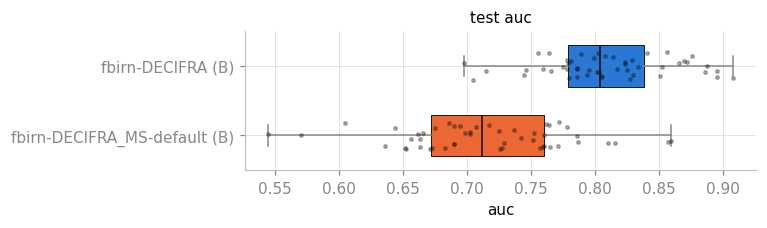

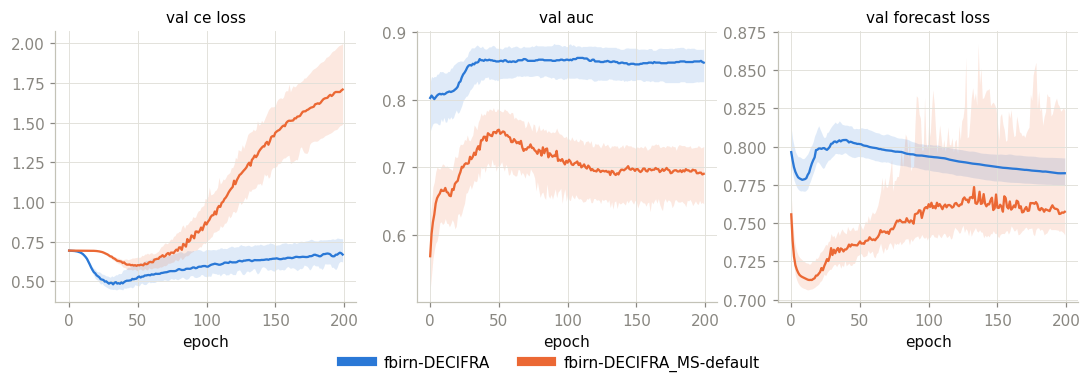

In [6]:
# chart chrome: recessive grid and axes, muted ticks; palette slots in fixed order
INK, MUTED = "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 1.5,
})
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
short = lambda name: name.replace("2_finetune-", "", 1)
rng = np.random.default_rng(0)

# color key: the experiment when few, else model (+ attractor group) with experiments grouped by it
many = len(summary) > len(SLOTS)
if many:
    key = summary.model + summary.group.map(lambda x: f" · {x}" if pd.notna(x) else "")
    exps = key.sort_values(kind="stable").index
else:
    key = pd.Series(summary.index.map(short), index=summary.index)
    exps = summary.index
color = {k: SLOTS[i % len(SLOTS)] for i, k in enumerate(dict.fromkeys(key[exps]))}
legend = lambda fig: fig.legend([plt.Line2D([], [], color=c, lw=6) for c in color.values()], list(color),
                                frameon=False, loc="upper center", ncol=min(len(color), 4), bbox_to_anchor=(0.5, 0))


def save(fig, name):
    if OUT_DIR:
        fig.savefig(os.path.join(ROOT, OUT_DIR, f"{name}.png"))


# scores: a box per experiment over its cells, one panel per test set
cols = SCORES
fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols) + 2, 1 + 0.32 * len(exps)),
                         sharex=True, sharey=True, squeeze=False)
for ax, col in zip(axes[0], cols):
    data = [results.loc[results.experiment == e, col].dropna() for e in exps]
    box = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                     medianprops={"color": INK}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for patch, e in zip(box["boxes"], exps):
        patch.set(facecolor=color[key[e]], edgecolor=INK, linewidth=0.6)
    for i, d in enumerate(data, 1):
        ax.scatter(d, i + rng.uniform(-0.2, 0.2, len(d)), s=5, color=INK, alpha=0.3, zorder=3)
    ax.set(title=col.replace("_", " "), xlabel=METRIC)

labels = [short(e) + ("" if pd.isna(summary.group[e]) else f" ({summary.group[e]})") for e in exps]
axes[0, 0].set_yticks(range(1, len(exps) + 1))
axes[0, 0].set_yticklabels(labels)
axes[0, 0].invert_yaxis()
if many:
    legend(fig)
save(fig, "scores")
plt.show()

# learning curves: median over the cells of each color key per epoch, IQR band
q = (logs.assign(key=logs.experiment.map(key)).drop(columns="experiment")
     .groupby(["key", "epoch"]).quantile([0.25, 0.5, 0.75]).unstack())
present = [c for c in CURVES if c in logs and logs[c].notna().any()]
fig, axes = plt.subplots(1, len(present), figsize=(4 * len(present), 3.2), squeeze=False)
for ax, col in zip(axes[0], present):
    for k, c in color.items():
        cur = q.loc[k]
        ax.plot(cur.index, cur[(col, 0.5)], color=c)
        ax.fill_between(cur.index, cur[(col, 0.25)], cur[(col, 0.75)], color=c, alpha=0.15, lw=0)
    ax.set(title=col.replace("_", " "), xlabel="epoch")
legend(fig)
save(fig, "curves")
plt.show()